In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence, pad_packed_sequence
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, confusion_matrix
import itertools

In [2]:
!nvidia-smi

Sun Oct 11 19:15:29 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 610.88                 KMD Version: 610.88        CUDA UMD Version: 13.3     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                  Driver-Model | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 3050 ...  WDDM  |   00000000:01:00.0 Off |                  N/A |
| N/A   48C    P8              6W /   60W |     570MiB /   6144MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [3]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cuda


## Dataset Parsing & Formulation (Variable-Length Sequences)

In [6]:
class SpokenArabicDigitDataset(Dataset):
    def __init__(self, file_path):
        self.sequences = []
        self.labels = []

        with open(file_path, 'r') as f:
            current_seq = []

            for line in f:
                # Strip hidden characters like \r and trailing whitespaces
                line = line.strip()

                # An empty line designates the end of a variable-length sequence block[cite: 3]
                if not line:
                    if current_seq:
                        self.sequences.append(torch.tensor(np.array(current_seq, dtype=np.float32)))
                        current_seq = []
                else:
                    try:
                        # Parse the 13-dimensional MFCC feature vectors[cite: 3]
                        features = list(map(float, line.split()))
                        if len(features) == 13:
                            current_seq.append(features)
                    except ValueError:
                        # Safely skip non-numerical metadata headers in the text file
                        continue

            # Catch the final sequence if the file does not end with a blank line
            if current_seq:
                self.sequences.append(torch.tensor(np.array(current_seq, dtype=np.float32)))

        # The dataset is sorted by Speaker, then Digit, then Repetition (10 repetitions per digit)
        for idx in range(len(self.sequences)):
            label = (idx // 10) % 10
            self.labels.append(label)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return self.sequences[idx], torch.tensor(self.labels[idx], dtype=torch.long)

## Data Collation (Padding) & Loaders

In [7]:
def collate_fn(batch):
    # Sort batch by sequence length (descending) for pack_padded_sequence
    batch.sort(key=lambda x: x[0].shape[0], reverse=True)
    sequences, labels = zip(*batch)

    lengths = torch.tensor([seq.shape[0] for seq in sequences])

    # Pad variable-length sequences dynamically[cite: 3]
    padded_seqs = pad_sequence(sequences, batch_first=True)
    labels = torch.stack(labels)

    return padded_seqs, labels, lengths

# Assuming the text files are in the working directory
train_dataset = SpokenArabicDigitDataset('Train_Arabic_Digit.txt')
test_dataset = SpokenArabicDigitDataset('Test_Arabic_Digit.txt')

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True, collate_fn=collate_fn)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False, collate_fn=collate_fn)

print(f"Loaded Train Utterances: {len(train_dataset)} | Test Utterances: {len(test_dataset)}")

Loaded Train Utterances: 6600 | Test Utterances: 2200


## Unified Model Architecture (with Sequence Packing)

In [8]:
class SpokenDigitClassifier(nn.Module):
    def __init__(self, input_size=13, hidden_size=64, num_layers=2, num_classes=10, rnn_type='LSTM'):
        super(SpokenDigitClassifier, self).__init__()
        self.rnn_type = rnn_type

        # Input size updated to 13 for MFCC features[cite: 3]
        if rnn_type == 'RNN':
            self.rnn = nn.RNN(input_size, hidden_size, num_layers, batch_first=True)
        elif rnn_type == 'LSTM':
            self.rnn = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True)
        elif rnn_type == 'GRU':
            self.rnn = nn.GRU(input_size, hidden_size, num_layers, batch_first=True)

        self.fc = nn.Linear(hidden_size, num_classes)

    def forward(self, x, lengths):
        packed_input = pack_padded_sequence(x, lengths.cpu(), batch_first=True, enforce_sorted=True)

        if self.rnn_type == 'LSTM':
            packed_output, (hn, cn) = self.rnn(packed_input)
        else:
            packed_output, hn = self.rnn(packed_input)

        # Use the final hidden state of the top layer
        out = self.fc(hn[-1, :, :])
        return out

## Training & Evaluation Functions (Adapted for packed lengths)

In [9]:
def train_and_evaluate_audio(model, train_loader, learning_rate=0.001):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)

    prev_train_loss = float('inf')
    epoch = 1
    loss_history = []

    while True:
        model.train()
        running_loss = 0.0

        for sequences, labels, lengths in train_loader:
            sequences, labels = sequences.to(device), labels.to(device)
            optimizer.zero_grad()

            outputs = model(sequences, lengths)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * sequences.size(0)

        avg_train_loss = running_loss / len(train_loader.dataset)
        loss_history.append(avg_train_loss)

        if abs(avg_train_loss - prev_train_loss) < 1e-4:
            break

        prev_train_loss = avg_train_loss
        epoch += 1

    return model, loss_history, epoch

def get_audio_accuracy(model, data_loader):
    model.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for sequences, labels, lengths in data_loader:
            sequences, labels = sequences.to(device), labels.to(device)
            outputs = model(sequences, lengths)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    return (correct / total) * 100

## Hyperparameter Tuning Loop

In [10]:
hidden_sizes = [32, 64, 128]
num_layers_list = [1, 2]
rnn_types = ['RNN', 'LSTM', 'GRU']

tuning_results_audio = []
loss_histories_audio = {}
trained_models_dict_audio = {}

for rnn_type, hidden_size, num_layers in itertools.product(rnn_types, hidden_sizes, num_layers_list):
    print(f"Training Audio {rnn_type} | Neurons: {hidden_size} | Layers: {num_layers}...")

    model = SpokenDigitClassifier(hidden_size=hidden_size, num_layers=num_layers, rnn_type=rnn_type)
    trained_model, loss_history, epochs_run = train_and_evaluate_audio(model, train_loader)

    train_acc = get_audio_accuracy(trained_model, train_loader)
    test_acc = get_audio_accuracy(trained_model, test_loader)

    config_name = f"{rnn_type}_N{hidden_size}_L{num_layers}"
    loss_histories_audio[config_name] = loss_history
    trained_models_dict_audio[config_name] = trained_model

    tuning_results_audio.append({
        'Model': rnn_type, 'Neurons': hidden_size, 'Layers': num_layers,
        'Epochs': epochs_run, 'Train Acc (%)': round(train_acc, 2), 'Test Acc (%)': round(test_acc, 2)
    })

Training Audio RNN | Neurons: 32 | Layers: 1...
Training Audio RNN | Neurons: 32 | Layers: 2...
Training Audio RNN | Neurons: 64 | Layers: 1...
Training Audio RNN | Neurons: 64 | Layers: 2...
Training Audio RNN | Neurons: 128 | Layers: 1...
Training Audio RNN | Neurons: 128 | Layers: 2...
Training Audio LSTM | Neurons: 32 | Layers: 1...
Training Audio LSTM | Neurons: 32 | Layers: 2...
Training Audio LSTM | Neurons: 64 | Layers: 1...
Training Audio LSTM | Neurons: 64 | Layers: 2...
Training Audio LSTM | Neurons: 128 | Layers: 1...
Training Audio LSTM | Neurons: 128 | Layers: 2...
Training Audio GRU | Neurons: 32 | Layers: 1...
Training Audio GRU | Neurons: 32 | Layers: 2...
Training Audio GRU | Neurons: 64 | Layers: 1...
Training Audio GRU | Neurons: 64 | Layers: 2...
Training Audio GRU | Neurons: 128 | Layers: 1...
Training Audio GRU | Neurons: 128 | Layers: 2...


## Complete Summary Table of All Models

In [11]:
from IPython.display import display

results_audio_df = pd.DataFrame(tuning_results_audio)
results_audio_df.sort_values(by=['Test Acc (%)'], ascending=False, inplace=True)

print("Complete Summary Table (Audio MFCC Configurations):")
display(results_audio_df)

Complete Summary Table (Audio MFCC Configurations):


,Model,Neurons,Layers,Epochs,Train Acc (%),Test Acc (%)
9,LSTM,64,2,103,100.00,12.18
11,LSTM,128,2,62,99.98,11.00
14,GRU,64,1,165,100.00,11.00
3,RNN,64,2,925,99.42,10.91
8,LSTM,64,1,194,100.00,10.91
13,GRU,32,2,174,99.55,10.59
1,RNN,32,2,525,65.74,10.55
10,LSTM,128,1,86,100.00,10.41
4,RNN,128,1,776,56.06,10.36
2,RNN,64,1,71,56.35,10.36


## Best Model Summary Table

In [12]:
best_audio_summary = results_audio_df.head(1).copy()
print("Best Audio Model Summary Table:")
display(best_audio_summary)

Best Audio Model Summary Table:


,Model,Neurons,Layers,Epochs,Train Acc (%),Test Acc (%)
9,LSTM,64,2,103,100.0,12.18


## Plotting Curves

### Vanilla RNN Learning Curves

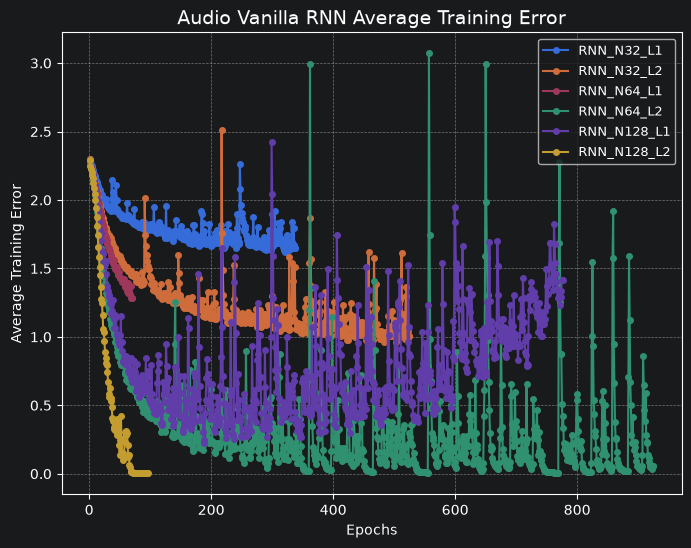

In [13]:
plt.figure(figsize=(8, 6))
for config, history in loss_histories_audio.items():
    if config.startswith('RNN'):
        plt.plot(range(1, len(history) + 1), history, marker='o', markersize=4, label=config)

plt.title('Audio Vanilla RNN Average Training Error', fontsize=14)
plt.xlabel('Epochs')
plt.ylabel('Average Training Error')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=9, loc='upper right')
plt.show()

### LSTM Learning Curves

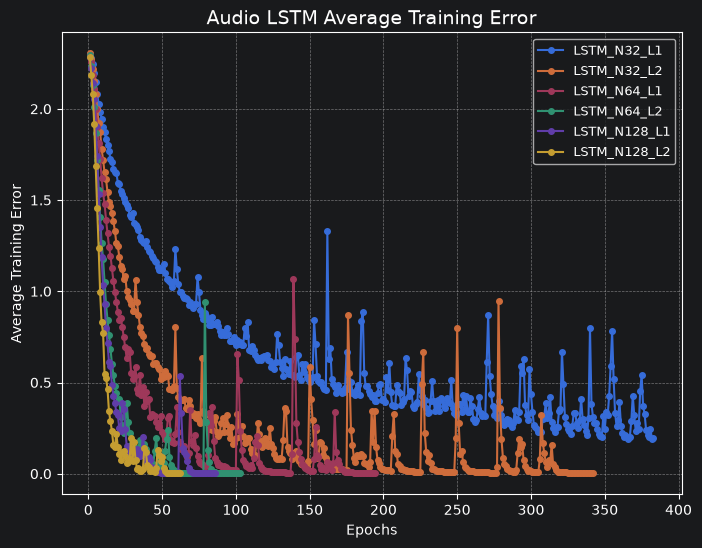

In [14]:
plt.figure(figsize=(8, 6))
for config, history in loss_histories_audio.items():
    if config.startswith('LSTM'):
        plt.plot(range(1, len(history) + 1), history, marker='o', markersize=4, label=config)

plt.title('Audio LSTM Average Training Error', fontsize=14)
plt.xlabel('Epochs')
plt.ylabel('Average Training Error')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=9, loc='upper right')
plt.show()

### GRU Learning Curves

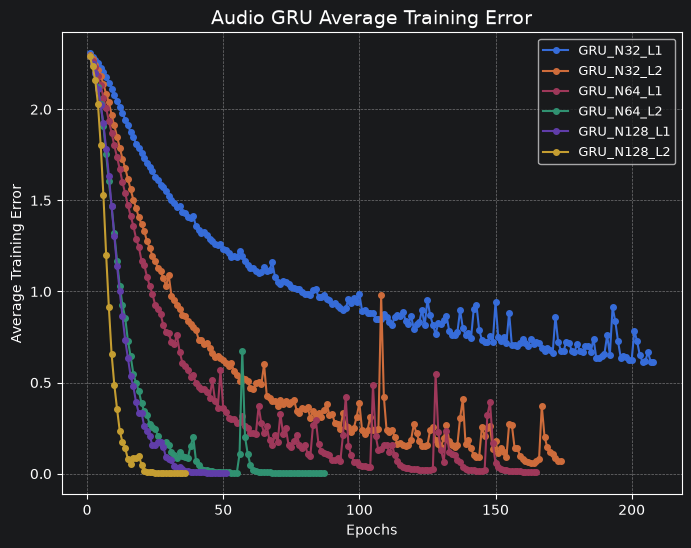

In [15]:
plt.figure(figsize=(8, 6))
for config, history in loss_histories_audio.items():
    if config.startswith('GRU'):
        plt.plot(range(1, len(history) + 1), history, marker='o', markersize=4, label=config)

plt.title('Audio GRU Average Training Error', fontsize=14)
plt.xlabel('Epochs')
plt.ylabel('Average Training Error')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=9, loc='upper right')
plt.show()

## Best Model Complete Confusion Matrix

Best Audio Configuration: LSTM_N64_L2


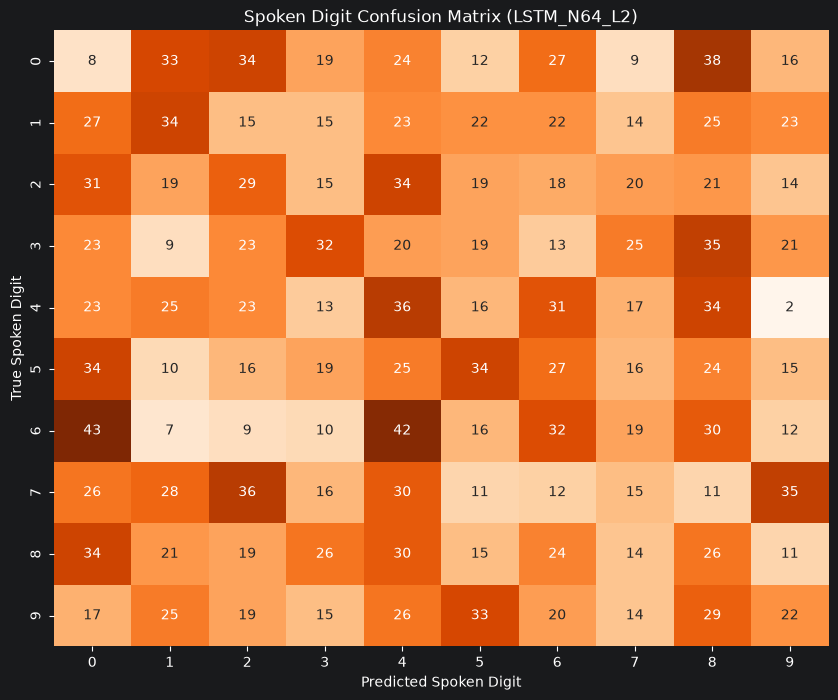

In [16]:
best_config = results_audio_df.iloc[0]
best_model_name = f"{best_config['Model']}_N{best_config['Neurons']}_L{best_config['Layers']}"
best_model = trained_models_dict_audio[best_model_name]

print(f"Best Audio Configuration: {best_model_name}")

def get_audio_preds(model, loader):
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for sequences, labels, lengths in loader:
            sequences = sequences.to(device)
            outputs = model(sequences, lengths)
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.numpy())
    return all_labels, all_preds

test_y, test_pred = get_audio_preds(best_model, test_loader)
cm = confusion_matrix(test_y, test_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges', cbar=False)
plt.xlabel('Predicted Spoken Digit')
plt.ylabel('True Spoken Digit')
plt.title(f'Spoken Digit Confusion Matrix ({best_model_name})')
plt.show()

## Qualitative Visualizations (MFCC Heatmaps)

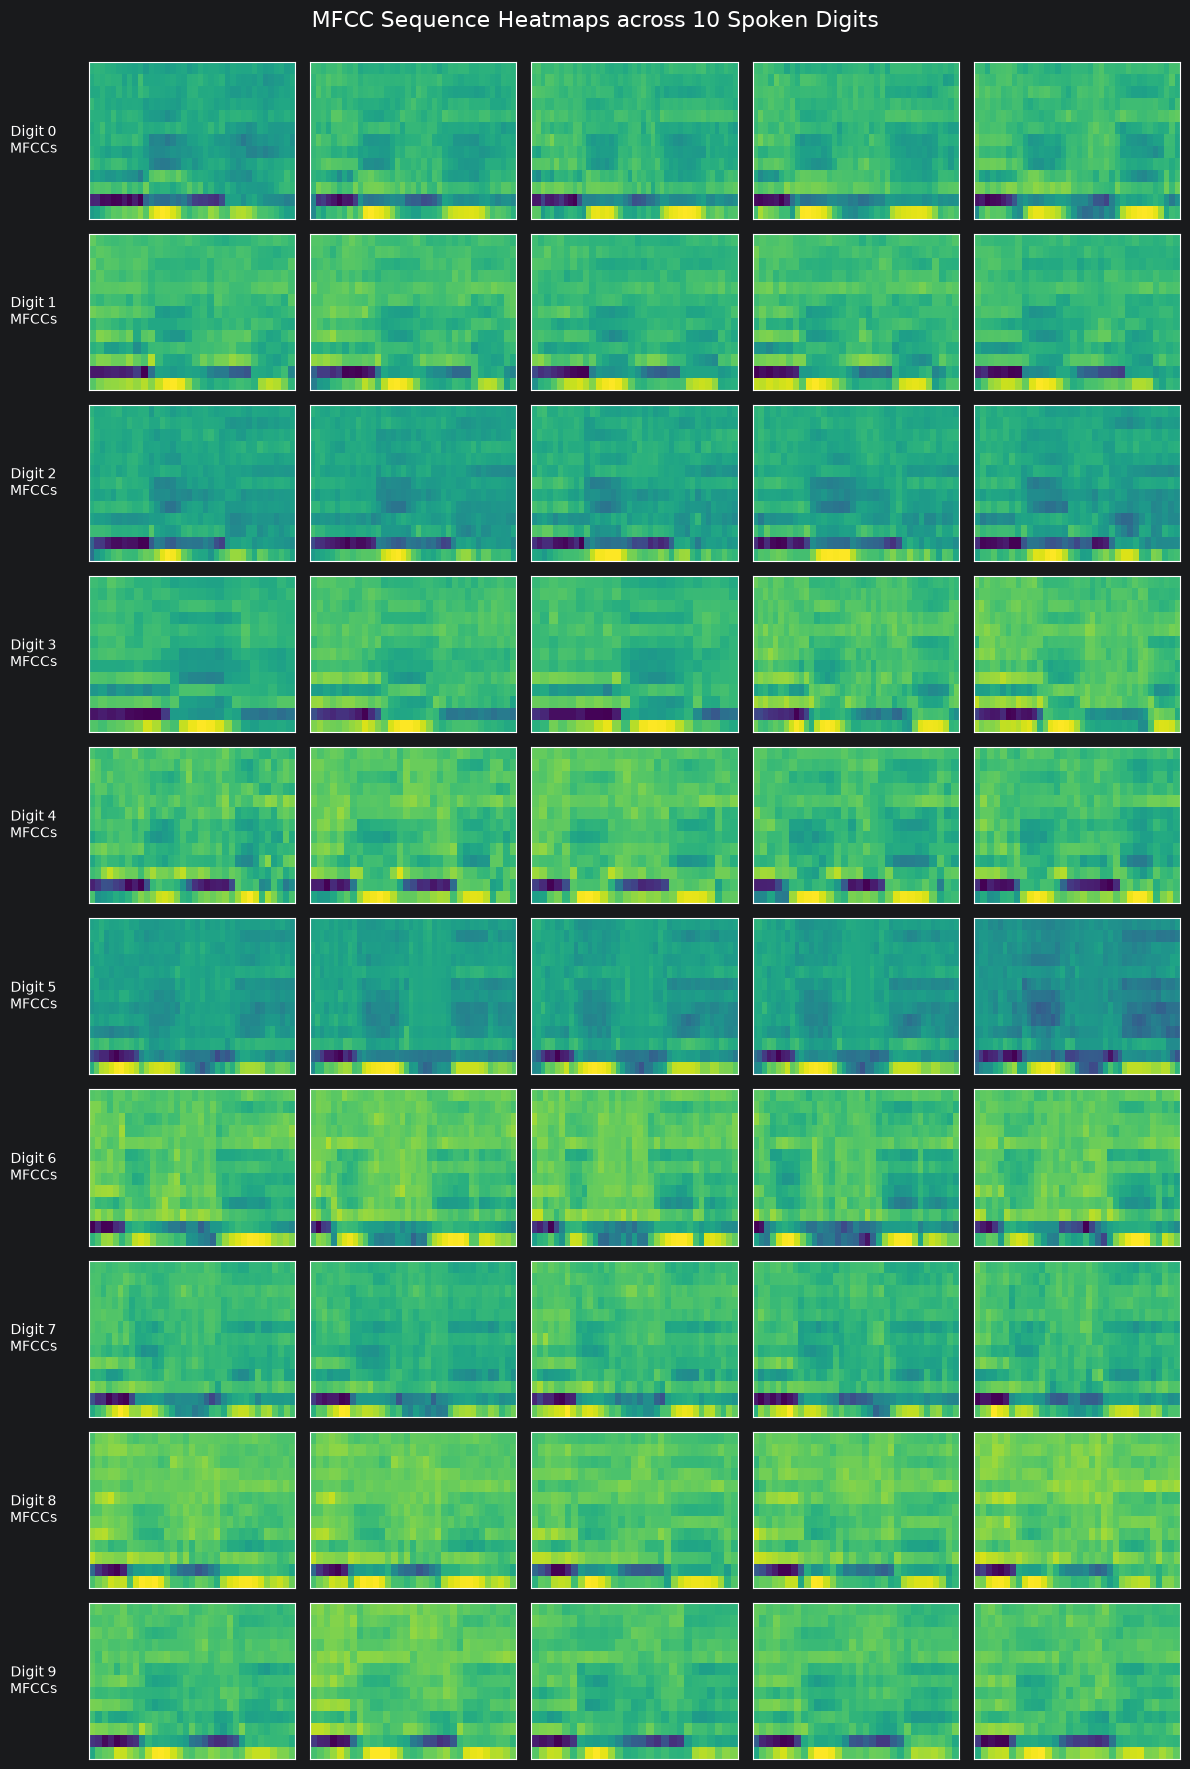

In [17]:
def plot_mfcc_heatmaps(dataset, samples_per_class=5, num_classes=10):
    fig, axes = plt.subplots(num_classes, samples_per_class, figsize=(12, 18))
    counts = {i: 0 for i in range(num_classes)}

    for mfcc_seq, label in dataset:
        lbl = label.item()
        if counts[lbl] < samples_per_class:
            ax = axes[lbl, counts[lbl]]

            # Transpose so time is on x-axis and 13 MFCC coefficients are on y-axis[cite: 3]
            ax.imshow(mfcc_seq.numpy().T, cmap='viridis', aspect='auto', origin='lower')
            ax.set_xticks([])
            ax.set_yticks([])

            if counts[lbl] == 0:
                ax.set_ylabel(f"Digit {lbl}\nMFCCs", rotation=0, labelpad=40, va='center')

            counts[lbl] += 1

        if all(c == samples_per_class for c in counts.values()):
            break

    plt.suptitle("MFCC Sequence Heatmaps across 10 Spoken Digits", fontsize=16)
    plt.tight_layout(rect=[0, 0, 1, 0.98])
    plt.show()

# Pass the raw dataset for unpadded visualization
plot_mfcc_heatmaps(train_dataset)